In [1]:
import pandas as pd
import numpy as np

# Load the cleaned dataset
df = pd.read_csv('../data/student-por-clean.csv')

# Display the first 5 rows to confirm successful loading
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [2]:
# Generate summary statistics for all numerical columns
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [3]:
# Select only numerical features
num_cols = df.select_dtypes(include=[np.number]).columns

# Create a comprehensive summary table with key statistical metrics
summary_table = pd.DataFrame({
    'Mean': df[num_cols].mean(),
    'Median': df[num_cols].median(),
    'Std Dev': df[num_cols].std(),
    'Min': df[num_cols].min(),
    'Max': df[num_cols].max(),
    'IQR': df[num_cols].quantile(0.75) - df[num_cols].quantile(0.25)
})

summary_table

,Mean,Median,Std Dev,Min,Max,IQR
age,16.744222,17.0,1.218138,15,22,2.0
Medu,2.514638,2.0,1.134552,0,4,2.0
Fedu,2.306626,2.0,1.099931,0,4,2.0
traveltime,1.568567,1.0,0.748660,1,4,1.0
studytime,1.930663,2.0,0.829510,1,4,1.0
failures,0.221880,0.0,0.593235,0,3,0.0
famrel,3.930663,4.0,0.955717,1,5,1.0
freetime,3.180277,3.0,1.051093,1,5,1.0
goout,3.184900,3.0,1.175766,1,5,2.0
Dalc,1.502311,1.0,0.924834,1,5,1.0


Key Observations (Numerical EDA)

1. Student Grades (G1, G2, G3): The mean final grade G3 is 11.91 with a median of 12.0, closely mirroring G1 (mean: 11.40) and G2 (mean: 11.57). Scores span from 0 to 19, showing consistent academic evaluation across periods with an IQR of 3.0 to 4.0 points.
2. Demographics & Study Habits: Student ages range from 15 to 22 years (mean: 16.74, median: 17.0). Weekly study time averages 1.93 (median: 2.0, corresponding to 2–5 hours per week), while average travel time is low at 1.57.
3. Absences & Variance: School absences show the highest dispersion with a standard deviation of 4.64 and a range from 0 to 32 days. The right skew is evident as the mean (3.66) is notably higher than the median (2.0).
4. Parental Education & Lifestyle: Both Mother's (Medu) and Father's (Fedu) education levels average around 2.3–2.5 (median: 2.0). Alcohol consumption remains relatively low overall, though weekend consumption (Walc mean: 2.28) is higher than weekday consumption (Dalc mean: 1.50).

Successfully created 4 visualizations!
Charts saved in: /Users/dori/Downloads/CAP_3764_2026_Fall_Team_1-integrate-visualizations/outputs/visualizations


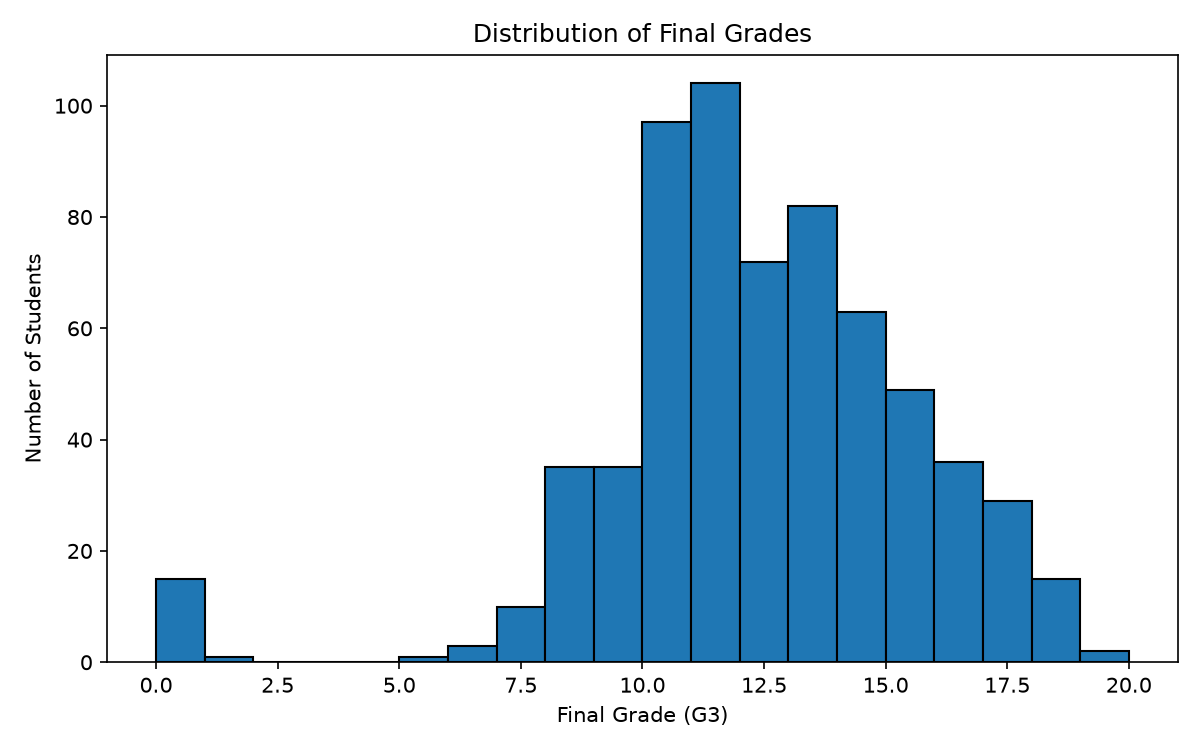

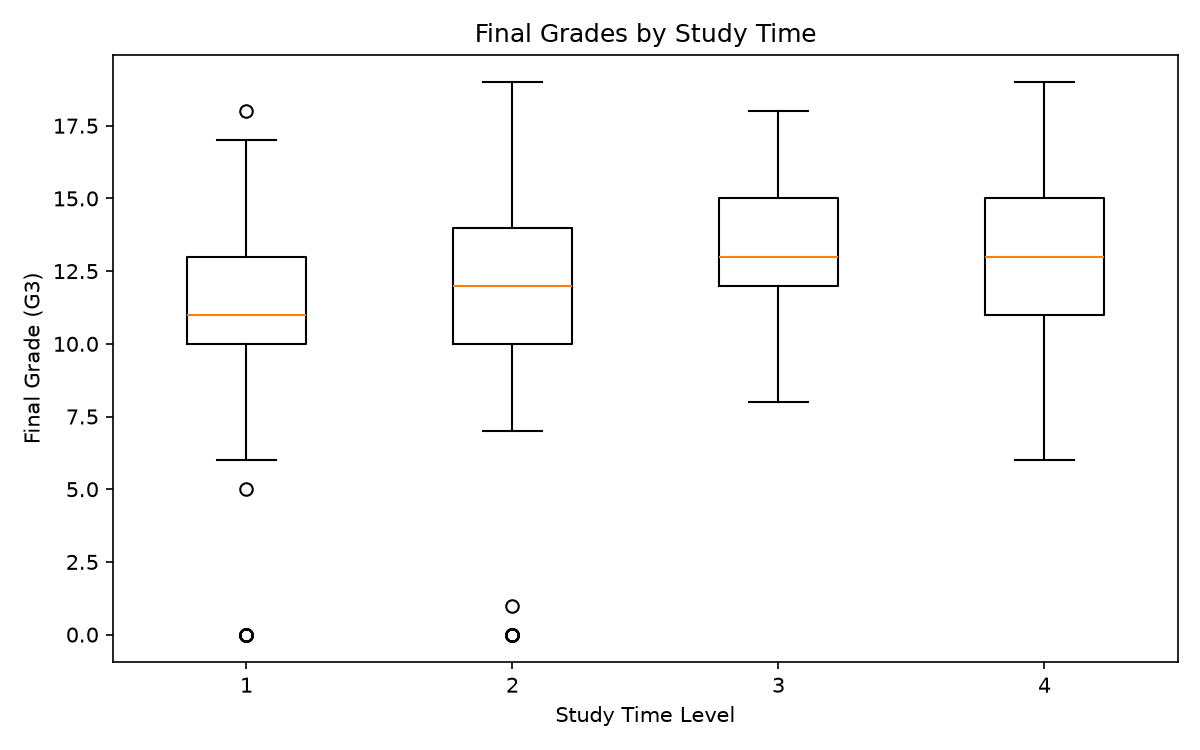

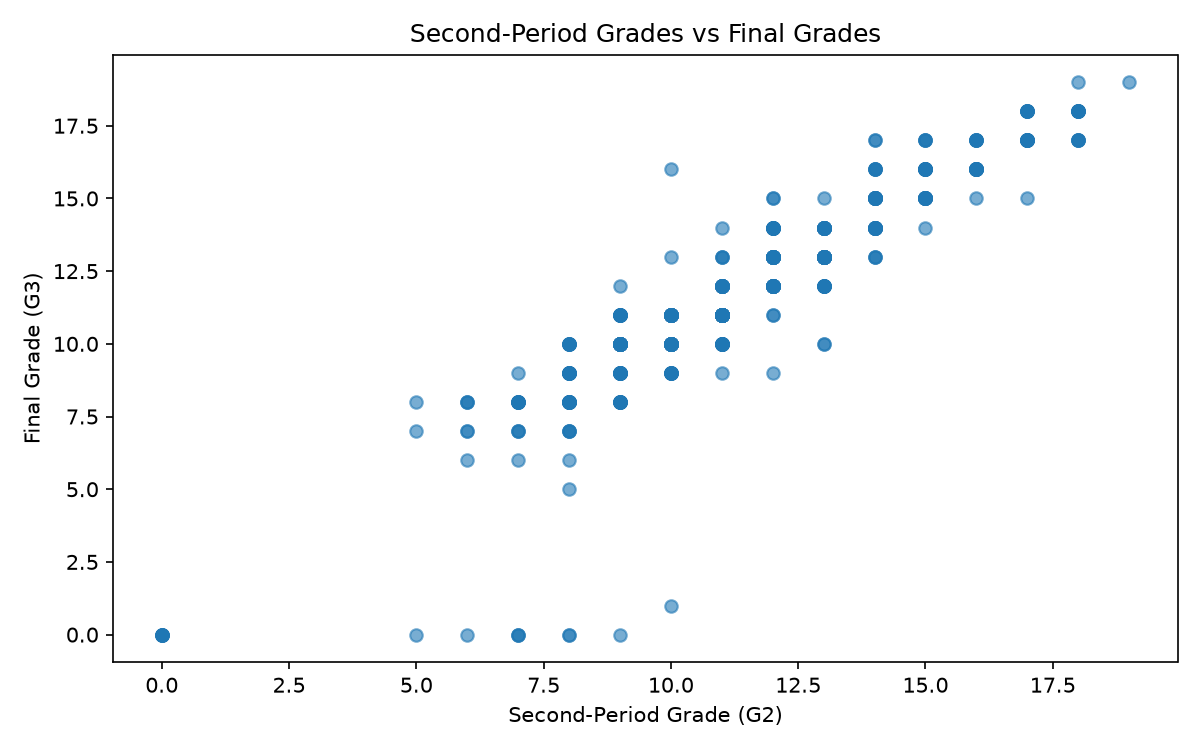

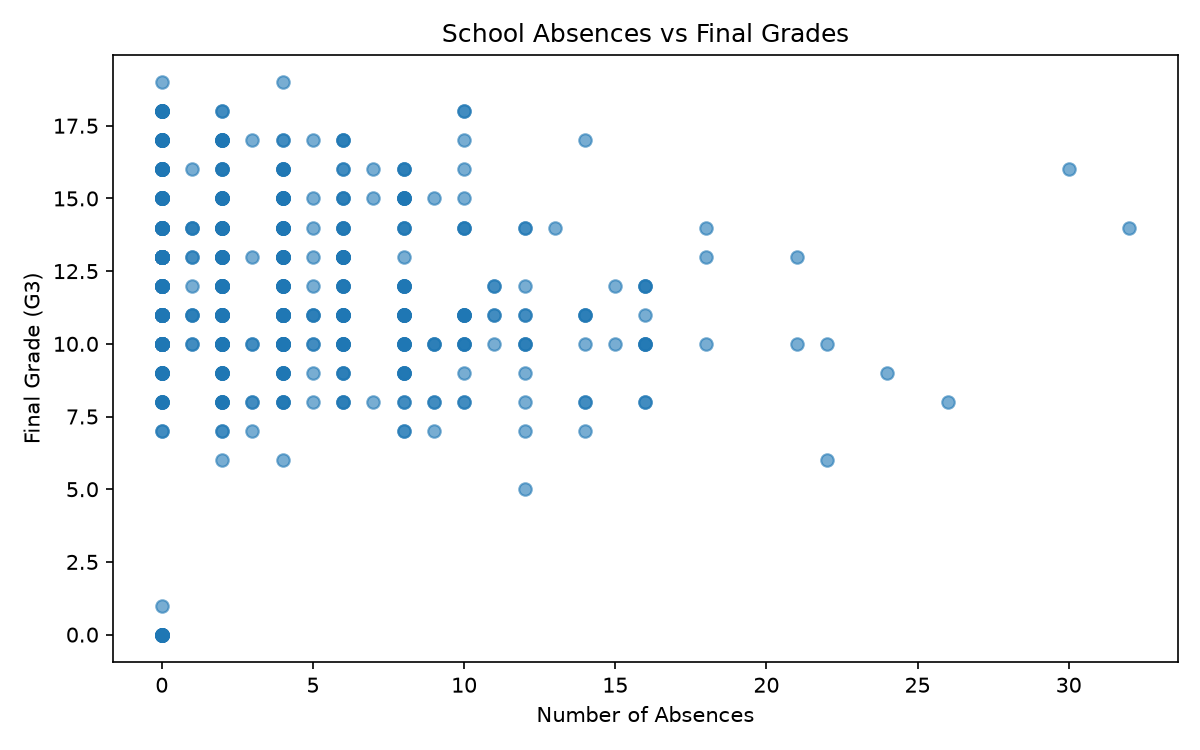

In [4]:
import sys
from pathlib import Path
from IPython.display import Image, display

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from my_modules.visualizations_module import create_visualizations

create_visualizations()

output_dir = project_root / "outputs" / "visualizations"
for filename in (
    "final_grade_distribution.png",
    "grades_by_studytime.png",
    "g2_vs_g3.png",
    "absences_vs_g3.png",
):
    display(Image(filename=str(output_dir / filename)))